# Practical 6 — Neural Networks for Microscopy Data

This practical introduces a compact neural-network workflow for a biological image-derived dataset.

The main dataset is a processed microscopy feature table containing only large objects. Each row is one object, the target is cell type (m0, m1, or m2), and the numerical columns are morphology, geometry, intensity, and chromatin measurements.

The notebook covers:

1. Reproducible setup and tensor basics
2. A minimal multilayer perceptron
3. Training and validation
4. Evaluation and interpretation
5. Loading and modelling the processed microscopy feature data

## Learning objectives

By the end of the practical, students should be able to:

- compute the output of a single artificial neuron manually;
- explain the role of weights, bias, and activation functions;
- describe a dense layer as a matrix transformation;
- convert biological tabular data into tensors;
- build a multilayer perceptron in PyTorch;
- explain logits, loss, gradients, and optimizer updates;
- write a complete training loop;
- compare different learning rates and network capacities;
- identify overfitting from train/validation curves;
- apply dropout, weight decay, and early stopping;
- reproduce the same basic architecture in Keras / TensorFlow;
- compare neural-network performance with classical ML baselines.


## 0. Setup

In [1]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    GroupShuffleSplit,
    GroupKFold,
)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier

RANDOM_STATE = 141026

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cuda


# Part I — One artificial neuron

## 1. Start with one sample

A neuron first computes:

$$
z = \mathbf{w}^T\mathbf{x} + b
$$

and then applies an activation function:

$$
a = f(z)
$$

We will calculate this manually before using any deep-learning library.


In [2]:
# Example input
x = np.array([0.8, -1.2, 0.3])
w = np.array([0.4, 0.7, -0.2])

b = 0.5

z = x @ w + b

print("x:", x)
print("w:", w)
print("bias:", b)
print("weighted sum z:", z)


x: [ 0.8 -1.2  0.3]
w: [ 0.4  0.7 -0.2]
bias: 0.5
weighted sum z: -0.07999999999999985


## 2. Visualise one neuron

The diagram makes the computation explicit:

$$
z = \sum_{j=1}^{p} w_j x_j + b
$$

The weighted inputs are added together with the bias. An activation function then converts the pre-activation value into the neuron output:

$$
a = f(z)
$$

The arrows labelled with weights show that each input contributes according to both its value and its learned weight.

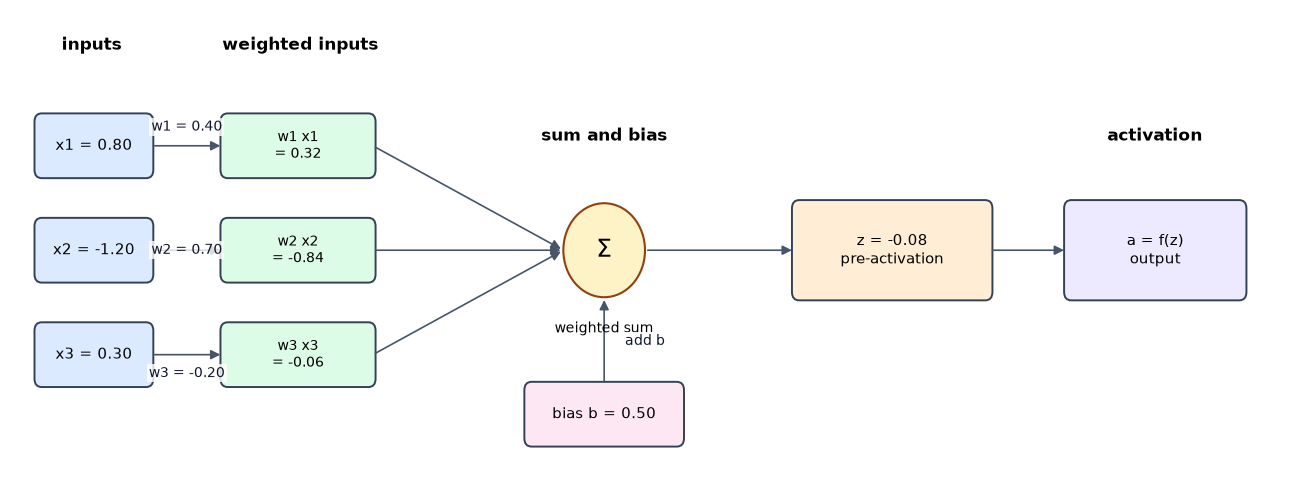

In [3]:


weighted_inputs = x * w

fig, ax = plt.subplots(figsize=(13, 5))
ax.set_xlim(0, 14)
ax.set_ylim(0, 4.5)
ax.axis("off")

def add_box(x0, y0, width, height, text, facecolor, fontsize=11):
    box = FancyBboxPatch(
        (x0, y0),
        width,
        height,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        linewidth=1.4,
        edgecolor="#334155",
        facecolor=facecolor,
    )
    ax.add_patch(box)
    ax.text(
        x0 + width / 2,
        y0 + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
    )

def add_arrow(x0, y0, x1, y1, label=None, label_offset=(0, 0)):
    arrow = FancyArrowPatch(
        (x0, y0),
        (x1, y1),
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=1.2,
        color="#475569",
    )
    ax.add_patch(arrow)
    if label is not None:
        ax.text(
            (x0 + x1) / 2 + label_offset[0],
            (y0 + y1) / 2 + label_offset[1],
            label,
            ha="center",
            va="center",
            fontsize=10,
            color="#0f172a",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5),
        )

input_y = [3.2, 2.2, 1.2]
for index, y_value in enumerate(input_y):
    add_box(
        0.3,
        y_value - 0.28,
        1.25,
        0.56,
        f"x{index + 1} = {x[index]:.2f}",
        "#dbeafe",
    )
    add_box(
        2.35,
        y_value - 0.28,
        1.65,
        0.56,
        f"w{index + 1} x{index + 1}\n= {weighted_inputs[index]:.2f}",
        "#dcfce7",
        fontsize=10,
    )
    add_arrow(
        1.55,
        y_value,
        2.35,
        y_value,
        label=f"w{index + 1} = {w[index]:.2f}",
        label_offset=(0, 0.18 if index == 0 else -0.18 if index == 2 else 0),
    )
    add_arrow(4.0, y_value, 6.1, 2.2)

sum_node = Circle((6.55, 2.2), 0.45, facecolor="#fef3c7", edgecolor="#92400e", linewidth=1.5)
ax.add_patch(sum_node)
ax.text(6.55, 2.2, "Σ", ha="center", va="center", fontsize=18)
ax.text(6.55, 1.45, "weighted sum", ha="center", va="center", fontsize=10)

add_box(5.7, 0.35, 1.7, 0.56, f"bias b = {b:.2f}", "#fce7f3")
add_arrow(6.55, 0.91, 6.55, 1.75, label="add b", label_offset=(0.45, 0))

add_arrow(7.0, 2.2, 8.65, 2.2)
add_box(8.65, 1.75, 2.15, 0.9, f"z = {z:.2f}\npre-activation", "#ffedd5")
add_arrow(10.8, 2.2, 11.65, 2.2)
add_box(11.65, 1.75, 1.95, 0.9, "a = f(z)\noutput", "#ede9fe")

ax.text(0.9, 4.12, "inputs", ha="center", fontsize=12, fontweight="bold")
ax.text(3.2, 4.12, "weighted inputs", ha="center", fontsize=12, fontweight="bold")
ax.text(6.55, 3.25, "sum and bias", ha="center", fontsize=12, fontweight="bold")
ax.text(12.62, 3.25, "activation", ha="center", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

### Questions

- What is the role of each weight?
- What would happen if one weight became very large?
- Why do we need the bias term?


## 2. Bias experiment

In [4]:
bias_values = [-2.0, 0.0, 2.0]

for b in bias_values:
    z = x @ w + b
    print(f"b = {b:>4}: z = {z:.3f}")


b = -2.0: z = -2.580
b =  0.0: z = -0.580
b =  2.0: z = 1.420


### Interpretation

The bias shifts the neuron response independently of the input values.

For a linear decision boundary:

$$
\mathbf{w}^T\mathbf{x} + b = 0
$$

changing $b$ moves the boundary without changing its orientation.


# Part II — Activation functions

## 3. Implement common activations manually

In [5]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

def leaky_relu(x, alpha=0.1):
    return np.where(x > 0, x, alpha * x)


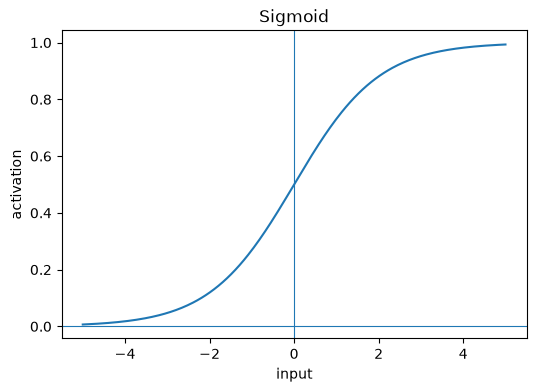

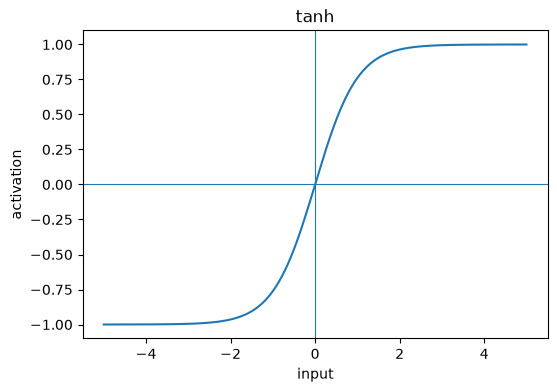

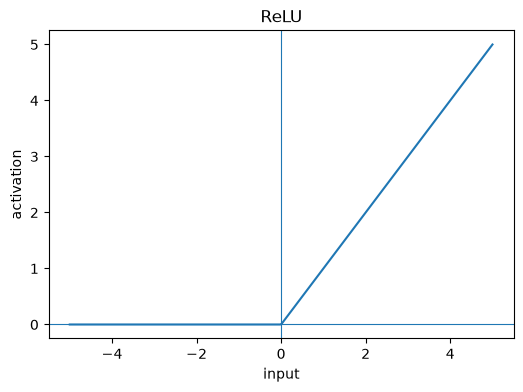

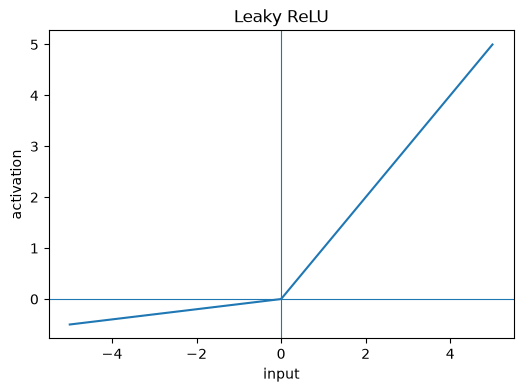

In [6]:
x_grid = np.linspace(-5, 5, 300)

activations = {
    "Sigmoid": sigmoid(x_grid),
    "tanh": tanh(x_grid),
    "ReLU": relu(x_grid),
    "Leaky ReLU": leaky_relu(x_grid)
}

for name, values in activations.items():
    plt.figure(figsize=(6, 4))
    plt.plot(x_grid, values)
    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)
    plt.title(name)
    plt.xlabel("input")
    plt.ylabel("activation")
    plt.show()


# Part III — From one neuron to one dense layer

## 5. Matrix form

A layer with several neurons can be written as:

$$
\mathbf{z} = W\mathbf{x} + \mathbf{b}
$$

Each row of $W$ corresponds to one neuron.


In [7]:
x = np.array([0.8, -1.2, 0.3])

W = np.array([
    [0.2,  0.4, -0.7],
    [0.8, -0.1,  0.3],
    [-0.5, 0.9,  0.2],
    [0.1,  0.4,  0.6]
])

b = np.array([0.1, -0.2, 0.0, 0.3])

z = W @ x + b
a = relu(z)

print("x shape:", x.shape)
print("W shape:", W.shape)
print("b shape:", b.shape)
print("z shape:", z.shape)
print("activated output:", a)


x shape: (3,)
W shape: (4, 3)
b shape: (4,)
z shape: (4,)
activated output: [0.   0.65 0.   0.08]


## 6. Dataset description

The student-facing file is week6/large_objects_m0_m1_m2_processed.csv. It was prepared from the microscopy object table before distribution.

Preparation choices:

- Keep rows with image_kind equal to large_object.
- Keep the classic segmentation variant so the same biological object is not represented four times by different segmentation methods.
- Convert the original group labels M0, M1, and M2 to the target values m0, m1, and m2.
- Replace the original experiment identifier with an anonymised sample_group identifier. This is metadata used for leakage-safe splitting, not a predictive feature.
- Retain numerical measurements describing object morphology, geometry, intensity, texture, and chromatin-related properties.
- Remove paths, object names, segmentation-method fields, image metadata, labels, and other identifiers that are not needed for modelling.

The resulting table contains 381 objects, 49 numerical features, 85 sample groups, and the following class counts:

| cell_type | objects |
|---|---:|
| m0 | 132 |
| m1 | 104 |
| m2 | 145 |

Because several objects can originate from the same sample or experiment, observations from one sample_group must not be split between train, validation, and test sets.

In [8]:
from pathlib import Path

DATA_PATH = Path("week6/large_objects_m0_m1_m2_processed.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("large_objects_m0_m1_m2_processed.csv")

df = pd.read_csv(DATA_PATH)

print("Data path:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.value_counts())

Data path: large_objects_m0_m1_m2_processed.csv
Shape: (381, 51)


,cell_type,sample_group,volume_voxels,volume_units3,surface_area_units2,sphericity,equivalent_diameter_units,centroid_z,centroid_y,centroid_x,...,surface_to_volume_ratio,equivalent_sphere_radius_units,inertia_eigval_0,inertia_eigval_1,inertia_eigval_2,inertia_anisotropy,centroid_z_norm_stack,centroid_y_norm_stack,centroid_x_norm_stack,distance_to_stack_center_units
0,m0,experiment_001,276743,276743.0,27809.851562,0.738476,80.852355,22.525292,75.822294,84.355601,...,0.100490,40.426177,1478.293368,904.118152,710.562956,0.519336,0.441672,0.486040,0.544230,7.940009
1,m0,experiment_001,283593,283593.0,29347.027344,0.711296,81.514017,25.895449,72.709143,78.685549,...,0.103483,40.757008,1532.955541,1024.523643,651.346833,0.575104,0.488593,0.466084,0.504395,4.936473
2,m0,experiment_001,251874,251874.0,29778.589844,0.647693,78.354072,24.460726,74.602913,77.450868,...,0.118228,39.177036,1627.794318,1089.952015,643.241744,0.604838,0.470399,0.521699,0.499683,3.776818
3,m0,experiment_001,245243,245243.0,29148.757812,0.650023,77.660348,24.147352,91.744735,80.677369,...,0.118857,38.830174,1662.394337,1062.755666,692.584305,0.583381,0.473477,0.588107,0.517163,14.619684
4,m0,experiment_001,282939,282939.0,29995.000000,0.694860,81.451308,23.316542,73.392434,78.215523,...,0.106012,40.725654,1582.797830,969.810146,738.997793,0.533107,0.457187,0.470464,0.501382,4.496454


float64    37
int64      12
object      2
Name: count, dtype: int64

## Universal biological data-preparation checklist

Use this checklist before starting the neural-network analysis. Tick an item only after inspecting the data or documenting a justified decision.

### Scientific purpose and provenance

- [ ] Is the biological question and prediction task stated clearly?
- [ ] Is the unit of observation clear: here, one row should represent one large microscopy object?
- [ ] Do I know where the data came from and how the measurements were generated?
- [ ] Have I recorded the data version, preprocessing history, and transformations already applied?

### Table shape and identifiers

- [ ] Is the table tidy: one observation per row, one variable per column, and one value per cell?
- [ ] If the original assay had features in rows and samples in columns, was it transposed into the format expected by the analysis tool?
- [ ] Are row names, column names, and identifiers clear, unique, stable, and free from accidental index columns?
- [ ] Can every feature and observation be traced back to its source?
- [ ] Are the feature matrix and metadata aligned by an explicit identifier rather than by row order?


In [9]:

display(pd.Series(df.columns, name="column"))


display(df.dtypes.rename("dtype").to_frame())


display(df.isna().sum().sort_values(ascending=False).head(15).rename("missing").to_frame())


for column in ["cell_type", "sample_group"]:
    print(f"{column}: {df[column].nunique()} unique values")
    display(df[column].value_counts(dropna=False).head(10).rename("count").to_frame())

0                            cell_type
1                         sample_group
2                        volume_voxels
3                        volume_units3
4                  surface_area_units2
5                           sphericity
6            equivalent_diameter_units
7                           centroid_z
8                           centroid_y
9                           centroid_x
10                             bbox_z0
11                             bbox_y0
12                             bbox_x0
13                             bbox_z1
14                             bbox_y1
15                             bbox_x1
16                        bbox_depth_z
17                       bbox_height_y
18                        bbox_width_x
19                  bbox_volume_voxels
20                  bbox_fill_fraction
21                      mean_intensity
22                    median_intensity
23                       min_intensity
24                       max_intensity
25                       

,dtype
cell_type,object
sample_group,object
volume_voxels,int64
volume_units3,float64
surface_area_units2,float64
sphericity,float64
equivalent_diameter_units,float64
centroid_z,float64
centroid_y,float64
centroid_x,float64


,missing
surface_area_units2,13
sphericity,13
projected_circularity,13
surface_to_volume_ratio,13
sample_group,0
volume_voxels,0
equivalent_diameter_units,0
centroid_z,0
centroid_y,0
volume_units3,0


cell_type: 3 unique values


,count
cell_type,
m2,145
m0,132
m1,104


sample_group: 85 unique values


,count
sample_group,
experiment_004,22
experiment_071,22
experiment_080,14
experiment_001,13
experiment_081,13
experiment_069,12
experiment_005,12
experiment_068,12
experiment_075,11



### Types, values, and measurement meaning

- [ ] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?
- [ ] Are units, scales, encodings, reference categories, and detection limits understood?
- [ ] Have I checked impossible values, inconsistent labels, unexpected categories, constant features, and extreme values?
- [ ] Are normalization, scaling, log transformation, and batch-correction steps documented?

### Missing values

- [ ] Have I detected missing values using the dataset's actual missing-value representations, not only NaN?
- [ ] Have I measured missingness by row, column, group, and relevant batch or time variable?
- [ ] Do I know whether missingness is structural, technical, or plausibly related to the biology or target?
- [ ] Have I justified whether to retain, remove, or impute missing values?
- [ ] If imputing, will the imputer be fitted on training data only and then applied to validation and test data?


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 51 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   cell_type                         381 non-null    object 
 1   sample_group                      381 non-null    object 
 2   volume_voxels                     381 non-null    int64  
 3   volume_units3                     381 non-null    float64
 4   surface_area_units2               368 non-null    float64
 5   sphericity                        368 non-null    float64
 6   equivalent_diameter_units         381 non-null    float64
 7   centroid_z                        381 non-null    float64
 8   centroid_y                        381 non-null    float64
 9   centroid_x                        381 non-null    float64
 10  bbox_z0                           381 non-null    int64  
 11  bbox_y0                           381 non-null    int64  
 12  bbox_x0 

In [11]:
display(df.describe().T)


display(df.isna().sum().sort_values(ascending=False).head(15).rename("missing").to_frame())


,count,mean,std,min,25%,50%,75%,max
volume_voxels,381.0,8.112129e+05,4.128121e+06,1.772930e+05,3.000220e+05,3.762040e+05,5.310970e+05,6.180274e+07
volume_units3,381.0,8.112129e+05,4.128121e+06,1.772930e+05,3.000220e+05,3.762040e+05,5.310970e+05,6.180274e+07
surface_area_units2,368.0,4.781240e+04,2.956593e+04,1.940683e+04,3.071611e+04,3.833912e+04,5.163522e+04,1.922112e+05
sphericity,368.0,6.468251e-01,1.049543e-01,3.452301e-01,5.690141e-01,6.565045e-01,7.210297e-01,8.586280e-01
equivalent_diameter_units,381.0,9.682969e+01,3.396765e+01,6.969971e+01,8.305864e+01,8.956567e+01,1.004751e+02,4.905347e+02
centroid_z,381.0,2.792631e+01,5.114021e+00,1.600000e+01,2.471158e+01,2.758301e+01,3.031702e+01,4.844828e+01
centroid_y,381.0,1.063140e+02,4.846952e+01,3.900000e+01,7.939970e+01,9.248645e+01,1.171447e+02,5.275000e+02
centroid_x,381.0,1.042225e+02,4.271740e+01,3.000000e+01,7.914662e+01,9.122094e+01,1.140194e+02,4.215000e+02
bbox_z0,381.0,7.669291e+00,4.182775e+00,0.000000e+00,6.000000e+00,7.000000e+00,9.000000e+00,3.200000e+01
bbox_y0,381.0,2.770604e+01,2.135163e+01,0.000000e+00,1.500000e+01,2.200000e+01,3.400000e+01,1.960000e+02


,missing
surface_area_units2,13
sphericity,13
projected_circularity,13
surface_to_volume_ratio,13
sample_group,0
volume_voxels,0
equivalent_diameter_units,0
centroid_z,0
centroid_y,0
volume_units3,0


In [12]:

constant_features = [column for column in df.columns if df[column].nunique(dropna=False) <= 1]
constant_features


[]

In [13]:

display(df['cell_type'].value_counts().sort_index().rename("objects").to_frame())
display(df['sample_group'].value_counts().to_frame("objects_per_group"))

,objects
cell_type,
m0,132
m1,104
m2,145


,objects_per_group
sample_group,
experiment_004,22
experiment_071,22
experiment_080,14
experiment_001,13
experiment_081,13
...,...
experiment_062,1
experiment_060,1
experiment_059,1


In [14]:
candidate_features = df.select_dtypes(include=np.number).columns.tolist()

print("Candidate numerical features:", len(candidate_features))
print(candidate_features[:10])

Candidate numerical features: 49
['volume_voxels', 'volume_units3', 'surface_area_units2', 'sphericity', 'equivalent_diameter_units', 'centroid_z', 'centroid_y', 'centroid_x', 'bbox_z0', 'bbox_y0']



### Replicates, dependence, and grouping

- [ ] Have I checked for exact duplicates and near-duplicate observations?
- [ ] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?
- [ ] Is the independent biological unit identified by a grouping variable?
- [ ] Will all related observations and their derivatives remain in the same train, validation, and test split?
- [ ] If augmented or synthetic observations were created, is their provenance recorded and reproducible?

### Target, leakage, and study design

- [ ] Is the target defined before modelling, with its classes checked for balance and validity?
- [ ] Have I excluded identifiers, post-outcome variables, duplicated target information, and other leakage sources from the features?
- [ ] Have I identified batch, site, plate, subject, cohort, treatment, sex, age, time, or other possible confounders?
- [ ] Have I checked whether the target is associated with a technical or grouping variable?
- [ ] Does the planned split represent the biological generalization question?


In [15]:
candidate_features = df.select_dtypes(include=np.number).columns.tolist()

print("Candidate numerical features:", len(candidate_features))
print(candidate_features[:10])

Candidate numerical features: 49
['volume_voxels', 'volume_units3', 'surface_area_units2', 'sphericity', 'equivalent_diameter_units', 'centroid_z', 'centroid_y', 'centroid_x', 'bbox_z0', 'bbox_y0']



### Reproducibility and decision record

- [ ] Are random seeds, software versions, file names, and input/output shapes recorded?
- [ ] Are all preprocessing steps placed in a reproducible pipeline?
- [ ] Have I recorded unresolved data-quality concerns and the decisions made about them?
- [ ] Can another person explain what each row, column, feature, target, and grouping variable means?


## 8. Small exploratory data analysis

Before splitting or fitting a model, inspect the target balance, group sizes, and several representative feature distributions. These plots are for exploration, not feature selection.

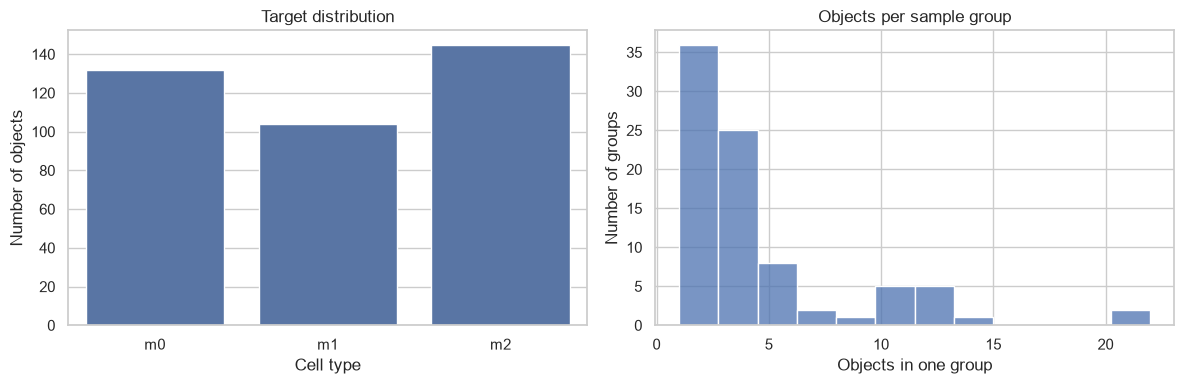

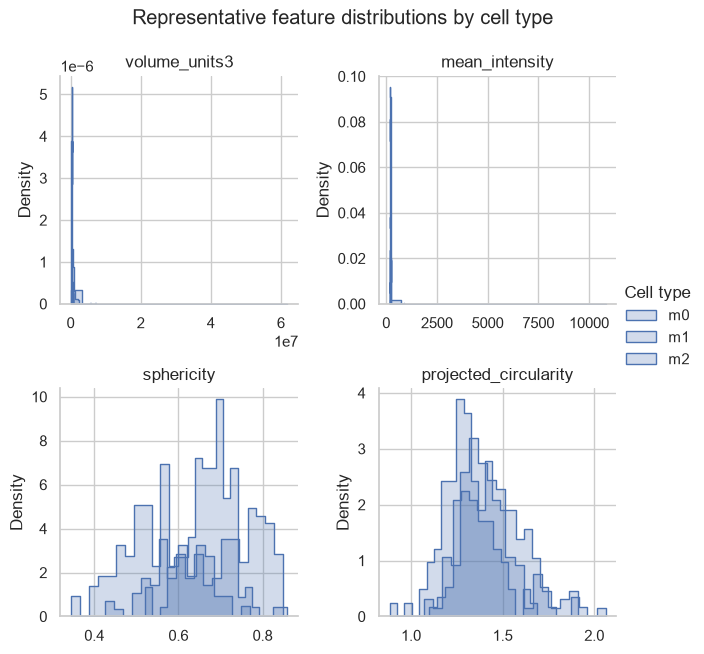

In [16]:
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

plot_features = [
    column for column in [
        "volume_units3",
        "mean_intensity",
        "sphericity",
        "projected_circularity",
    ]
    if column in df.columns
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df,
    x="cell_type",
    order=["m0", "m1", "m2"],
    ax=axes[0],
)
axes[0].set_title("Target distribution")
axes[0].set_xlabel("Cell type")
axes[0].set_ylabel("Number of objects")

group_sizes = df["sample_group"].value_counts()
sns.histplot(group_sizes, bins=12, ax=axes[1])
axes[1].set_title("Objects per sample group")
axes[1].set_xlabel("Objects in one group")
axes[1].set_ylabel("Number of groups")

plt.tight_layout()
plt.show()

if plot_features:
    long_features = df.melt(
        id_vars=["cell_type"],
        value_vars=plot_features,
        var_name="feature",
        value_name="value",
    )
    g = sns.FacetGrid(
        long_features,
        col="feature",
        col_wrap=2,
        hue="cell_type",
        sharex=False,
        sharey=False,
        height=3.2,
    )
    g.map_dataframe(
        sns.histplot,
        bins=20,
        element="step",
        stat="density",
        common_norm=False,
    )
    g.add_legend(title="Cell type")
    g.set_titles("{col_name}")
    g.fig.suptitle("Representative feature distributions by cell type", y=1.02)
    plt.show()

## 9. Association between the target and numerical features

The target is categorical, while the predictors are numerical. Two descriptive measures are useful:

- Mutual information estimates how much information a feature contains about the cell-type label.
- Eta squared measures the fraction of feature variance explained by differences between target groups.

For a feature X and target Y:

$$
I(X;Y)
=
\sum_{x,y}
p(x,y)
\log
\left(
\frac{p(x,y)}{p(x)p(y)}
\right)
$$

The formula compares the observed joint distribution with the distribution expected if X and Y were independent.

- If X and Y are independent, mutual information is 0.
- Larger values indicate stronger statistical dependence.
- Mutual information is not directional and does not prove biological causation.

These statistics are exploratory. They are not used as a substitute for group-aware evaluation.

,feature,eta_squared,mutual_information
0,bbox_y1,0.198766,0.393736
1,centroid_y,0.234275,0.383773
2,inertia_eigval_1,0.025528,0.377478
3,centroid_x,0.322398,0.357841
4,bbox_x1,0.306146,0.357505
5,inertia_eigval_0,0.022391,0.345199
6,chromatin_inner_area_px,0.023219,0.319404
7,surface_area_units2,0.402473,0.315076
8,projected_perimeter_px,0.356575,0.313204
9,projected_area_px,0.026228,0.303000


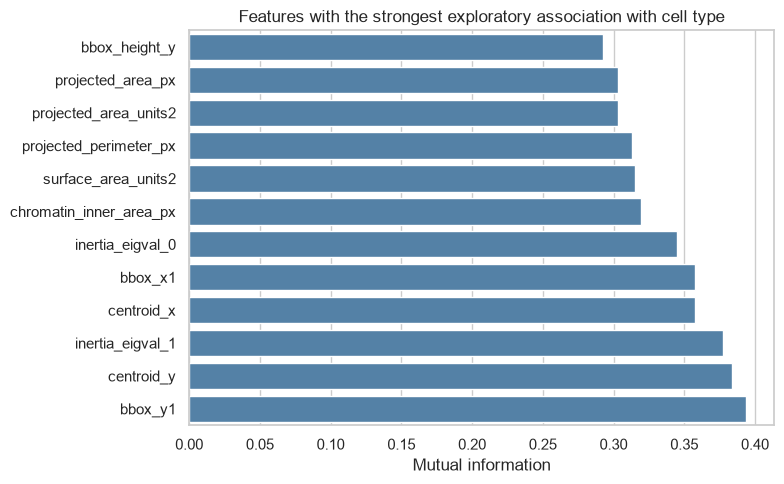

In [17]:
from sklearn.feature_selection import mutual_info_classif

association_rows = []
target_codes = df["cell_type"].map({"m0": 0, "m1": 1, "m2": 2})

for feature in candidate_features:
    values = df[feature]
    valid = values.notna() & target_codes.notna()
    feature_values = values[valid].to_numpy()
    feature_target = target_codes[valid].to_numpy()

    if len(feature_values) < 3 or np.isclose(np.var(feature_values), 0):
        eta_squared = np.nan
        mutual_information = 0.0
    else:
        grand_mean = feature_values.mean()
        grouped = pd.DataFrame({
            "value": feature_values,
            "target": feature_target,
        }).groupby("target")["value"]
        group_means = grouped.mean()
        group_counts = grouped.size()
        ss_between = ((group_means - grand_mean) ** 2 * group_counts).sum()
        ss_total = ((feature_values - grand_mean) ** 2).sum()
        eta_squared = ss_between / ss_total if ss_total > 0 else np.nan

        mutual_information = mutual_info_classif(
            pd.DataFrame({feature: feature_values}),
            feature_target,
            random_state=RANDOM_STATE,
        )[0]

    association_rows.append({
        "feature": feature,
        "eta_squared": eta_squared,
        "mutual_information": mutual_information,
    })

association = (
    pd.DataFrame(association_rows)
    .sort_values("mutual_information", ascending=False)
    .reset_index(drop=True)
)

display(association.head(15))

top_association = association.head(12).sort_values("mutual_information")
plt.figure(figsize=(8, 5))
sns.barplot(
    data=top_association,
    x="mutual_information",
    y="feature",
    color="steelblue",
)
plt.title("Features with the strongest exploratory association with cell type")
plt.xlabel("Mutual information")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 10. Define feature columns and metadata

The processed table has only two non-feature columns:

- cell_type: the classification target.
- sample_group: an anonymised sample/experiment grouping variable.

All remaining columns are numerical measurements and can be used as model inputs. The group column is kept separately so related observations can remain in the same data split.

In [18]:
TARGET = "cell_type"
GROUP_COLUMN = "sample_group"
META_COLUMNS = [TARGET, GROUP_COLUMN]

feature_cols = [column for column in df.columns if column not in META_COLUMNS]
X = df[feature_cols].copy()
y = df[TARGET].copy()
groups = df[GROUP_COLUMN].copy()

print("Number of features:", len(feature_cols))
print("Feature matrix shape:", X.shape)
print("Target values:", sorted(y.unique()))
print("Number of sample groups:", groups.nunique())

Number of features: 49
Feature matrix shape: (381, 49)
Target values: ['m0', 'm1', 'm2']
Number of sample groups: 85


# Part V — Group-aware splitting

## 12. Why random cell-level splitting may be wrong

If many cells come from the same image or biological sample, they are not independent.

Avoid:

```text
train: cells A1, A2, A3
test:  cells A4, A5
```

when all cells originate from the same sample.

Prefer splitting by the highest relevant independent biological unit.


In [19]:


splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train_full = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train_full = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_train_full = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

shared_groups = set(groups_train_full).intersection(groups_test)

print("Training objects:", len(X_train_full))
print("Test objects:", len(X_test))
print("Training groups:", groups_train_full.nunique())
print("Test groups:", groups_test.nunique())
print("Shared groups:", len(shared_groups))

Training objects: 283
Test objects: 98
Training groups: 68
Test groups: 17
Shared groups: 0


## 13. Create a validation set from training groups

In [20]:
val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

train_idx2, val_idx = next(
    val_splitter.split(
        X_train_full,
        y_train_full,
        groups=groups_train_full,
    )
)

X_train = X_train_full.iloc[train_idx2].copy()
X_val = X_train_full.iloc[val_idx].copy()
y_train = y_train_full.iloc[train_idx2].copy()
y_val = y_train_full.iloc[val_idx].copy()
groups_train = groups_train_full.iloc[train_idx2].copy()
groups_val = groups_train_full.iloc[val_idx].copy()

shared_train_val_groups = set(groups_train).intersection(groups_val)

print("Training objects:", len(X_train))
print("Validation objects:", len(X_val))
print("Training groups:", groups_train.nunique())
print("Validation groups:", groups_val.nunique())
print("Shared train/validation groups:", len(shared_train_val_groups))

Training objects: 239
Validation objects: 44
Training groups: 54
Validation groups: 14
Shared train/validation groups: 0


# Part VI — Scaling

## 14. Impute and standardize features

The inspection showed missing values in some derived geometry features. We will retain those rows and impute missing feature values with the training-set median.

Both the imputer and the scaler are fitted on training data only. The validation and test sets are transformed using those fitted objects, preventing information from those sets from influencing preprocessing.

In [21]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Missing values before imputation:")
print("train:", int(X_train.isna().sum().sum()))
print("validation:", int(X_val.isna().sum().sum()))
print("test:", int(X_test.isna().sum().sum()))

print("Scaled shapes:")
print("train:", X_train_scaled.shape)
print("validation:", X_val_scaled.shape)
print("test:", X_test_scaled.shape)
print("Missing values after imputation:", int(np.isnan(X_train_scaled).sum()))
print("First five training means:", X_train_scaled.mean(axis=0)[:5])
print("First five training standard deviations:", X_train_scaled.std(axis=0)[:5])

Missing values before imputation:
train: 44
validation: 0
test: 8
Scaled shapes:
train: (239, 49)
validation: (44, 49)
test: (98, 49)
Missing values after imputation: 0
First five training means: [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 -8.91894647e-17
  8.54732370e-17]
First five training standard deviations: [1. 1. 1. 1. 1.]


## Exploratory t-SNE visualization

The following plot provides a two-dimensional visual summary of the processed feature space. Points are coloured by cell type.

t-SNE is used here only for exploration. It is not a predictive model, and the embedding should not be used to evaluate the classifier or replace group-aware splitting.

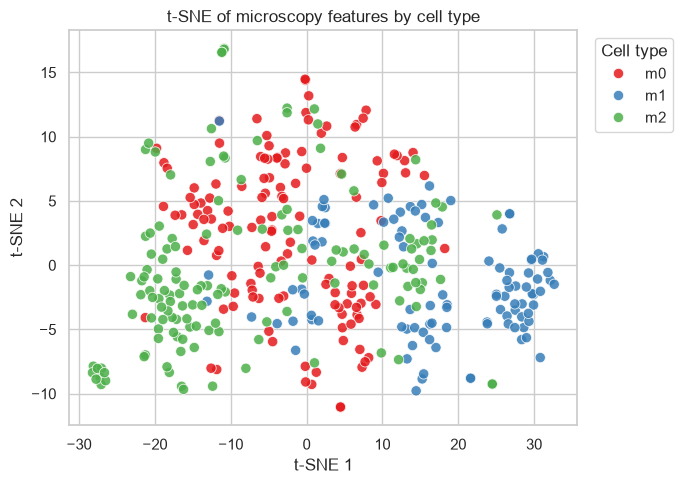

In [22]:

X_all_scaled = scaler.transform(imputer.transform(X))

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(X_all_scaled)

tsne_plot = pd.DataFrame({
    "TSNE1": X_tsne[:, 0],
    "TSNE2": X_tsne[:, 1],
    "cell_type": y.to_numpy(),
})

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=tsne_plot,
    x="TSNE1",
    y="TSNE2",
    hue="cell_type",
    hue_order=["m0", "m1", "m2"],
    palette="Set1",
    s=55,
    alpha=0.85,
)
plt.title("t-SNE of microscopy features by cell type")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Cell type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Part VII — Convert data to PyTorch tensors

In [23]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

class_names = sorted(y.unique())
class_to_index = {name: index for index, name in enumerate(class_names)}

y_train_t = torch.tensor(
    y_train.map(class_to_index).to_numpy(),
    dtype=torch.long,
)
y_val_t = torch.tensor(
    y_val.map(class_to_index).to_numpy(),
    dtype=torch.long,
)
y_test_t = torch.tensor(
    y_test.map(class_to_index).to_numpy(),
    dtype=torch.long,
)

print("Class mapping:", class_to_index)
print("Training tensor shapes:", X_train_t.shape, y_train_t.shape)
print("Validation tensor shapes:", X_val_t.shape, y_val_t.shape)
print("Test tensor shapes:", X_test_t.shape, y_test_t.shape)

Class mapping: {'m0': 0, 'm1': 1, 'm2': 2}
Training tensor shapes: torch.Size([239, 49]) torch.Size([239])
Validation tensor shapes: torch.Size([44, 49]) torch.Size([44])
Test tensor shapes: torch.Size([98, 49]) torch.Size([98])


In [24]:
y_test_t

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2])

## 16. Create Dataset and DataLoader objects

In [25]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 32

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 8
Validation batches: 2
Test batches: 4


# Part VIII — First MLP

## 17. Define a simple network

Suggested starting architecture:

$$
p \rightarrow 32 \rightarrow 16 \rightarrow K
$$

where:

- $p$ = number of input features
- $K$ = number of classes


In [26]:
class MLP(nn.Module):
    def __init__(self, input_dim, n_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, n_classes)
        )

    def forward(self, x):
        return self.network(x)


In [27]:
input_dim = X_train_scaled.shape[1]
n_classes = len(class_names)

model = MLP(
    input_dim=input_dim,
    n_classes=n_classes,
).to(DEVICE)

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=49, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)


## 18. Visualise the mMLP with torchview

The graph is generated from the actual PyTorch model, so it reflects the layers used in training. Tensor shapes make the transition from a batch of 49 microscopy features to three class logits explicit.



(process:13980): Pango-WARNING **: 00:25:34.919: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


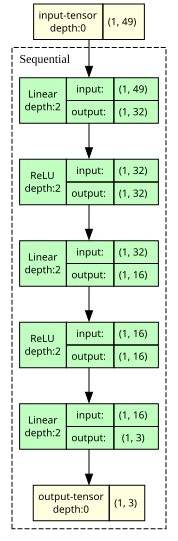

In [28]:
import shutil
from torchview import draw_graph

sample_input = torch.zeros((1, input_dim), dtype=torch.float32, device=DEVICE)
model_graph = draw_graph(
    model,
    input_data=sample_input,
    expand_nested=True,
    graph_name="microscopy_mlp",
)

if shutil.which("dot") is not None:
    display(model_graph.visual_graph)
else:
    print("Graphviz executable not found. Install Graphviz and reopen the notebook to render the image.")
    print("The torchview DOT source was generated successfully:")
    print(model_graph.visual_graph.source)

## 19. Count trainable parameters

In [29]:
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print("Trainable parameters:", count_parameters(model))


Trainable parameters: 2179


### Manual check

For:

```text
input_dim → 32 → 16 → K
```

calculate the parameter count manually before comparing with PyTorch.


# Part IX — Logits and loss

## 20. What does the model output?

For multiclass classification, the last layer outputs **logits**.

Do not add `Softmax()` inside the model when using:

```python
nn.CrossEntropyLoss()
```

because `CrossEntropyLoss` already handles the required transformation internally.


In [30]:
criterion = nn.CrossEntropyLoss()

with torch.no_grad():
    logits = model(X_train_t[:5].to(DEVICE))
    probabilities = torch.softmax(logits, dim=1)

print("Logits shape:", logits.shape)
print("Probabilities shape:", probabilities.shape)
print("Probabilities:")
display(probabilities.cpu().numpy())
print("Probability sums:", probabilities.sum(dim=1).cpu().numpy())

Logits shape: torch.Size([5, 3])
Probabilities shape: torch.Size([5, 3])
Probabilities:


array([[0.37815982, 0.33305818, 0.28878203],
       [0.38382733, 0.34343827, 0.27273437],
       [0.36691576, 0.33775038, 0.2953339 ],
       [0.36328375, 0.3389218 , 0.29779443],
       [0.3810108 , 0.34405077, 0.27493846]], dtype=float32)

Probability sums: [1. 1. 1. 1. 1.]


## Softmax before CrossEntropyLoss

CrossEntropyLoss expects raw, unnormalised logits. Internally, it applies the required log-softmax operation.

Applying Softmax first does not usually raise an error, but it changes the values passed to the loss and produces distorted loss and gradient signals. The following experiment compares the correct and incorrect calculations for increasingly confident logits.

In [31]:
from torch.nn.functional import softmax

base_logits = torch.tensor([[2.0, 0.0, -2.0]], dtype=torch.float32)
target = torch.tensor([0], dtype=torch.long)

softmax_rows = []

for scale in [1.0, 5.0, 20.0]:
    correct_logits = (scale * base_logits).clone().requires_grad_(True)
    correct_loss = nn.CrossEntropyLoss()(correct_logits, target)
    correct_loss.backward()
    correct_gradient_norm = correct_logits.grad.norm().item()

    wrong_logits = (scale * base_logits).clone().requires_grad_(True)
    probabilities_first = softmax(wrong_logits, dim=1)
    wrong_loss = nn.CrossEntropyLoss()(probabilities_first, target)
    wrong_loss.backward()
    wrong_gradient_norm = wrong_logits.grad.norm().item()

    softmax_rows.append({
        "logit_scale": scale,
        "correct_loss_from_logits": correct_loss.item(),
        "wrong_loss_after_softmax": wrong_loss.item(),
        "correct_gradient_norm": correct_gradient_norm,
        "wrong_gradient_norm": wrong_gradient_norm,
    })

softmax_comparison = pd.DataFrame(softmax_rows)
display(softmax_comparison)


,logit_scale,correct_loss_from_logits,wrong_loss_after_softmax,correct_gradient_norm,wrong_gradient_norm
0,1.0,0.142932,0.641652,1.781923e-01,1.113262e-01
1,5.0,0.000045,0.551474,6.421703e-05,4.082995e-05
2,20.0,0.000000,0.551445,4.248354e-18,2.701208e-18


# Part X — Training loop

## 21. The five central lines

```python
optimizer.zero_grad()
pred = model(X_batch)
loss = criterion(pred, y_batch)
loss.backward()
optimizer.step()
```

These implement:

$$
forward \rightarrow loss \rightarrow gradients \rightarrow update
$$


In [32]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 22. Training function

In [33]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

        pred = logits.argmax(dim=1)

        total_correct += (pred == y_batch).sum().item()
        total_samples += X_batch.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


## 23. Validation function

In [34]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        total_loss += loss.item() * X_batch.size(0)

        pred = logits.argmax(dim=1)

        total_correct += (pred == y_batch).sum().item()
        total_samples += X_batch.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


## 24. Full training loop

In [35]:
N_EPOCHS = 100

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(N_EPOCHS):
     train_loss, train_acc = train_one_epoch(
         model,
         train_loader,
         criterion,
         optimizer,
         DEVICE)

     val_loss, val_acc = evaluate(
         model,
         val_loader,
         criterion,
         DEVICE)

     history["train_loss"].append(train_loss)
     history["val_loss"].append(val_loss)
     history["train_acc"].append(train_acc)
     history["val_acc"].append(val_acc)

     if (epoch + 1) % 5 == 0:
         print(
             f"Epoch {epoch+1:03d} | "
             f"train loss={train_loss:.4f} | "
             f"val loss={val_loss:.4f} | "
             f"train acc={train_acc:.3f} | "
             f"val acc={val_acc:.3f}")


Epoch 005 | train loss=0.9240 | val loss=1.0625 | train acc=0.628 | val acc=0.273
Epoch 010 | train loss=0.7057 | val loss=1.0666 | train acc=0.682 | val acc=0.250
Epoch 015 | train loss=0.6007 | val loss=0.9943 | train acc=0.707 | val acc=0.432
Epoch 020 | train loss=0.5257 | val loss=0.8955 | train acc=0.757 | val acc=0.591
Epoch 025 | train loss=0.4550 | val loss=0.8039 | train acc=0.824 | val acc=0.659
Epoch 030 | train loss=0.3933 | val loss=0.7306 | train acc=0.866 | val acc=0.705
Epoch 035 | train loss=0.3424 | val loss=0.7332 | train acc=0.874 | val acc=0.705
Epoch 040 | train loss=0.3010 | val loss=0.6929 | train acc=0.904 | val acc=0.705
Epoch 045 | train loss=0.2670 | val loss=0.6790 | train acc=0.916 | val acc=0.727
Epoch 050 | train loss=0.2382 | val loss=0.6804 | train acc=0.950 | val acc=0.773
Epoch 055 | train loss=0.2123 | val loss=0.6510 | train acc=0.954 | val acc=0.773
Epoch 060 | train loss=0.1905 | val loss=0.6654 | train acc=0.962 | val acc=0.750
Epoch 065 | trai

## 25. Plot learning curves

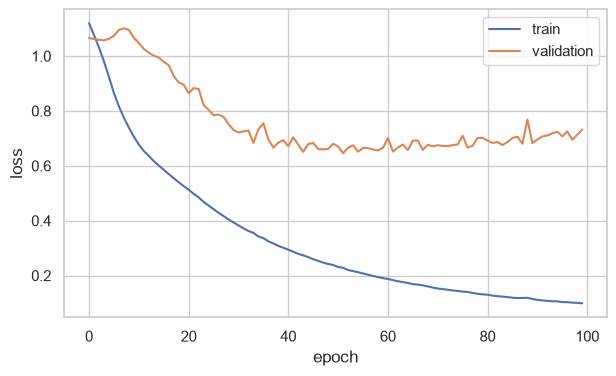

In [36]:
plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()


# Part XI — Inspect gradients

## 26. Gradient norms

After `loss.backward()`, every trainable parameter should usually have a gradient.

Inspect gradient magnitude.


In [37]:


for name, param in model.named_parameters():
     if param.grad is not None:
         print(name, tuple(param.shape), param.grad.norm().item())


network.0.weight (32, 49) 0.6452290415763855
network.0.bias (32,) 0.2008703649044037
network.2.weight (16, 32) 0.36324307322502136
network.2.bias (16,) 0.10439463704824448
network.4.weight (3, 16) 0.2885857820510864
network.4.bias (3,) 0.07239486277103424


### Questions

- What would gradients close to zero imply?
- What would extremely large gradients suggest?
- How might activation choice affect this?


# Part XII — Learning-rate experiment

## 27. Train identical models with different learning rates

Suggested values:

```python
1e-5
1e-3
1e-1
```

Keep everything else identical.


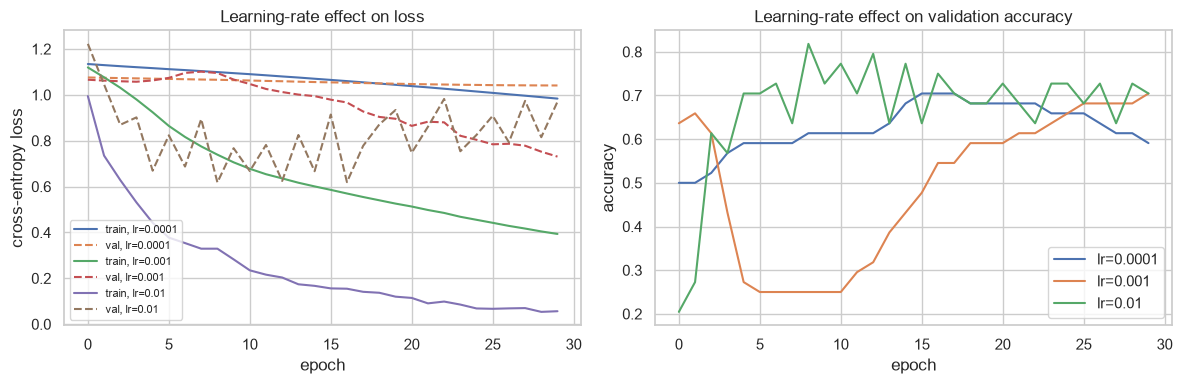

In [38]:
class FlexibleMLP(nn.Module):
    def __init__(self, input_dim, n_classes, hidden_dims=(32, 16), dropout=0.0):
        super().__init__()

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            current_dim = hidden_dim

        layers.append(nn.Linear(current_dim, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def fit_experiment(
    hidden_dims=(32, 16),
    lr=1e-3,
    weight_decay=0.0,
    dropout=0.0,
    epochs=30,
    patience=None,
):
    torch.manual_seed(RANDOM_STATE)

    experiment_model = FlexibleMLP(
        input_dim=input_dim,
        n_classes=n_classes,
        hidden_dims=hidden_dims,
        dropout=dropout,
    ).to(DEVICE)

    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    experiment_history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
    }

    best_state = None
    best_val_loss = np.inf
    best_epoch = epochs
    epochs_without_improvement = 0

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(
            experiment_model,
            train_loader,
            criterion,
            experiment_optimizer,
            DEVICE,
        )
        val_loss, val_acc = evaluate(
            experiment_model,
            val_loader,
            criterion,
            DEVICE,
        )

        experiment_history["train_loss"].append(train_loss)
        experiment_history["val_loss"].append(val_loss)
        experiment_history["train_acc"].append(train_acc)
        experiment_history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(experiment_model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if patience is not None and epochs_without_improvement >= patience:
            break

    if best_state is not None:
        experiment_model.load_state_dict(best_state)

    return experiment_model, experiment_history, best_epoch


learning_rates = [1e-4, 1e-3, 1e-2]
learning_rate_results = {}

for learning_rate in learning_rates:
    _, history_lr, best_epoch_lr = fit_experiment(
        lr=learning_rate,
        epochs=30,
    )
    learning_rate_results[learning_rate] = {
        "history": history_lr,
        "best_epoch": best_epoch_lr,
    }

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for learning_rate, result in learning_rate_results.items():
    history_lr = result["history"]
    axes[0].plot(history_lr["train_loss"], label=f"train, lr={learning_rate:g}")
    axes[0].plot(history_lr["val_loss"], linestyle="--", label=f"val, lr={learning_rate:g}")
    axes[1].plot(history_lr["val_acc"], label=f"lr={learning_rate:g}")

axes[0].set_title("Learning-rate effect on loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy loss")
axes[0].legend(fontsize=8)

axes[1].set_title("Learning-rate effect on validation accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### Expected patterns

- very small LR → slow convergence;
- reasonable LR → stable improvement;
- too large LR → oscillation / divergence / poor convergence.


# Part XIII — Width and depth

## 28. Compare model capacity

,architecture,hidden_dims,parameters,best_epoch,best_validation_accuracy,final_validation_accuracy
3,deep,"(64, 32, 16)",5859,35,0.772727,0.772727
1,medium,"(32, 16)",2179,34,0.727273,0.704545
2,wide,"(128,)",6787,35,0.727273,0.727273
0,small,"(8,)",427,35,0.500000,0.500000


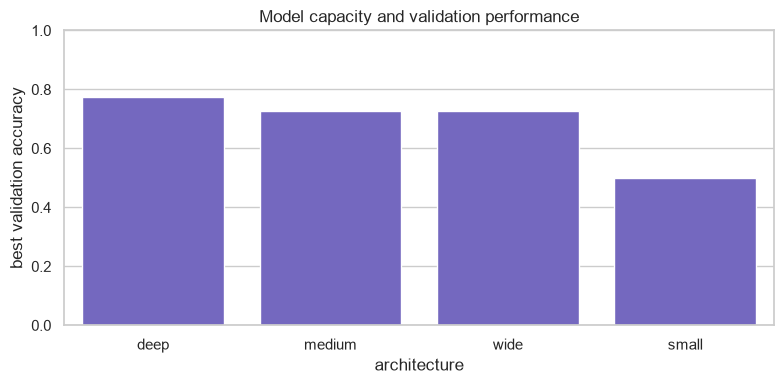

In [39]:
architectures = {
    "small": (8,),
    "medium": (32, 16),
    "wide": (128,),
    "deep": (64, 32, 16),
}

capacity_results = []
capacity_histories = {}

for name, hidden_dims in architectures.items():
    capacity_model, capacity_history, best_epoch_capacity = fit_experiment(
        hidden_dims=hidden_dims,
        lr=1e-3,
        epochs=35,
    )
    capacity_histories[name] = capacity_history
    capacity_results.append({
        "architecture": name,
        "hidden_dims": hidden_dims,
        "parameters": count_parameters(capacity_model),
        "best_epoch": best_epoch_capacity,
        "best_validation_accuracy": max(capacity_history["val_acc"]),
        "final_validation_accuracy": capacity_history["val_acc"][-1],
    })

capacity_table = pd.DataFrame(capacity_results).sort_values(
    "best_validation_accuracy",
    ascending=False,
)
display(capacity_table)

plt.figure(figsize=(8, 4))
sns.barplot(
    data=capacity_table,
    x="architecture",
    y="best_validation_accuracy",
    color="slateblue",
)
plt.ylim(0, 1)
plt.ylabel("best validation accuracy")
plt.title("Model capacity and validation performance")
plt.tight_layout()
plt.show()

### results table

| Architecture | Parameters | Train score | Validation score |
|---|---:|---:|---:|
| p → 8 → K | | | |
| p → 32 → 16 → K | | | |
| p → 128 → K | | | |
| p → 64 → 32 → 16 → K | | | |


# Part XIV — Deliberate overfitting

## 29. Build an oversized model

Try something intentionally excessive for the dataset:

```text
p → 256 → 128 → 64 → K
```

Train for more epochs than necessary.

Observe:

$$
training\ loss \downarrow
$$

while validation loss may eventually:

$$
validation\ loss \uparrow
$$


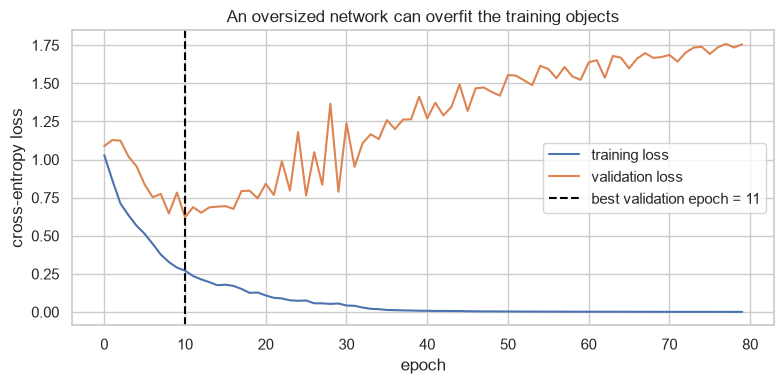

Best validation epoch: 11
Final training loss: 0.0008671549299856546
Final validation loss: 1.7557607685977763


In [40]:
oversized_model, oversized_history, oversized_best_epoch = fit_experiment(
    hidden_dims=(256, 128, 64),
    lr=1e-3,
    epochs=80)

plt.figure(figsize=(8, 4))
plt.plot(oversized_history["train_loss"], label="training loss")
plt.plot(oversized_history["val_loss"], label="validation loss")
plt.axvline(
    oversized_best_epoch - 1,
    color="black",
    linestyle="--",
    label=f"best validation epoch = {oversized_best_epoch}",
)
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("An oversized network can overfit the training objects")
plt.legend()
plt.tight_layout()
plt.show()

print("Best validation epoch:", oversized_best_epoch)
print("Final training loss:", oversized_history["train_loss"][-1])
print("Final validation loss:", oversized_history["val_loss"][-1])

# Part XV — Regularization

## 30. Weight decay

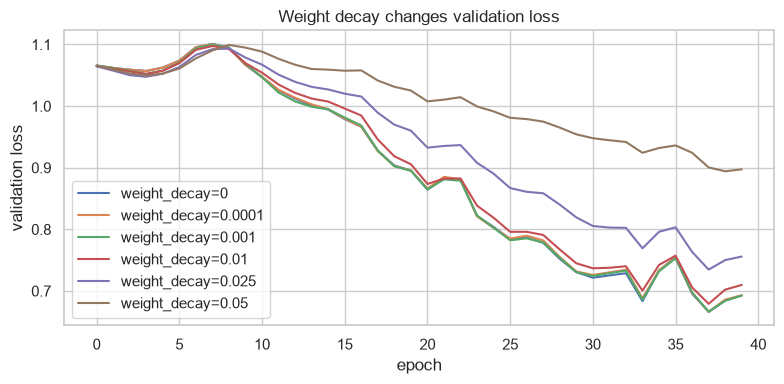

In [41]:
weight_decay_values = [0.0, 1e-4, 1e-3, 0.01, 0.025, 0.05]
weight_decay_results = {}

for weight_decay in weight_decay_values:
    _, history_wd, best_epoch_wd = fit_experiment(
        weight_decay=weight_decay,
        lr=1e-3,
        epochs=40,
    )
    weight_decay_results[weight_decay] = {
        "history": history_wd,
        "best_epoch": best_epoch_wd,
    }

plt.figure(figsize=(8, 4))
for weight_decay, result in weight_decay_results.items():
    plt.plot(
        result["history"]["val_loss"],
        label=f"weight_decay={weight_decay:g}",
    )

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Weight decay changes validation loss")
plt.legend()
plt.tight_layout()
plt.show()

## 31. Dropout

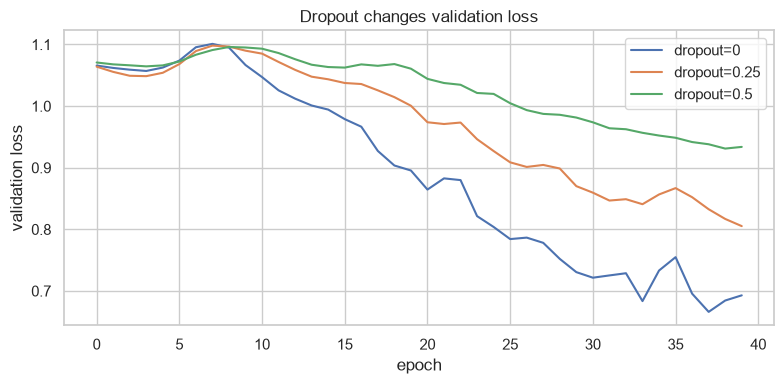

In [42]:
dropout_values = [0.0, 0.25, 0.5]
dropout_results = {}

for dropout_rate in dropout_values:
    _, history_dropout, best_epoch_dropout = fit_experiment(
        dropout=dropout_rate,
        lr=1e-3,
        epochs=40,
    )
    dropout_results[dropout_rate] = {
        "history": history_dropout,
        "best_epoch": best_epoch_dropout,
    }

plt.figure(figsize=(8, 4))
for dropout_rate, result in dropout_results.items():
    plt.plot(
        result["history"]["val_loss"],
        label=f"dropout={dropout_rate:g}",
    )

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Dropout changes validation loss")
plt.legend()
plt.tight_layout()
plt.show()

## 32. Early stopping

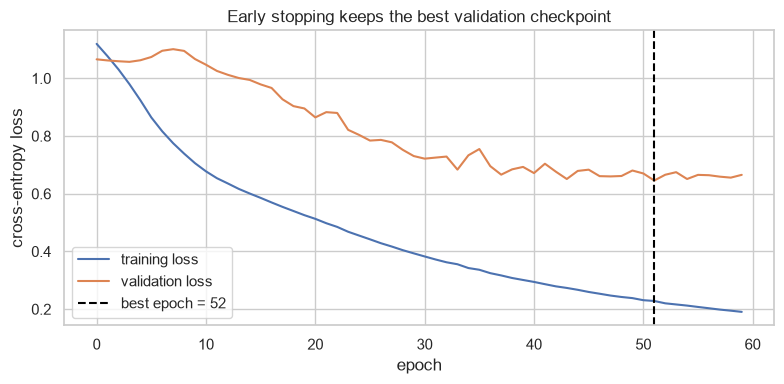

Epochs actually trained: 60
Best validation epoch: 52


In [43]:
early_stop_model, early_stop_history, early_stop_best_epoch = fit_experiment(
    hidden_dims=(32, 16),
    lr=1e-3,
    epochs=100,
    patience=8,
)

plt.figure(figsize=(8, 4))
plt.plot(early_stop_history["train_loss"], label="training loss")
plt.plot(early_stop_history["val_loss"], label="validation loss")
plt.axvline(
    early_stop_best_epoch - 1,
    color="black",
    linestyle="--",
    label=f"best epoch = {early_stop_best_epoch}",
)
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("Early stopping keeps the best validation checkpoint")
plt.legend()
plt.tight_layout()
plt.show()

print("Epochs actually trained:", len(early_stop_history["train_loss"]))
print("Best validation epoch:", early_stop_best_epoch)

## 33. Compare regularization strategies

| Model | Dropout | Weight decay | Early stopping | Validation score |
|---|---:|---:|---:|---:|
| Baseline | | | | |
| + Weight decay | | | | |
| + Dropout | | | | |
| + Early stopping | | | | |


,strategy,best_epoch,best_val_loss,best_val_accuracy
0,baseline,30,0.730554,0.704545
1,weight decay 1e-4,38,0.666168,0.727273
2,dropout 0.25,40,0.805244,0.727273
3,early stopping,52,0.645716,0.772727


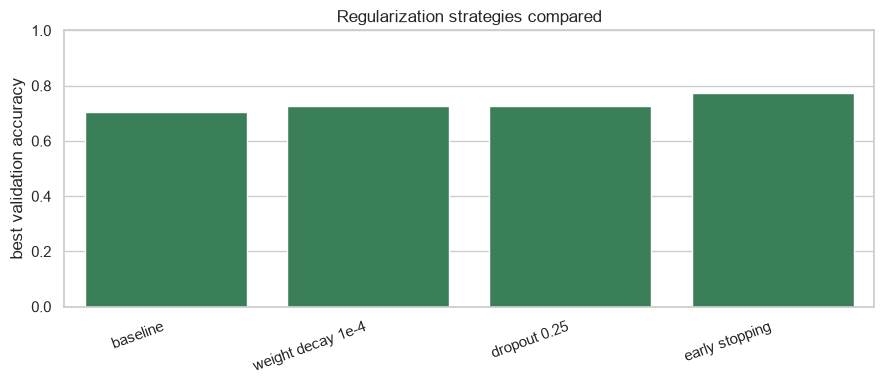

In [44]:
def best_validation_summary(history):
    best_index = int(np.argmin(history["val_loss"]))
    return {
        "best_epoch": best_index + 1,
        "best_val_loss": history["val_loss"][best_index],
        "best_val_accuracy": max(history["val_acc"]),
    }

regularization_summary = pd.DataFrame([
    {
        "strategy": "baseline",
        **best_validation_summary(learning_rate_results[1e-3]["history"]),
    },
    {
        "strategy": "weight decay 1e-4",
        **best_validation_summary(weight_decay_results[1e-4]["history"]),
    },
    {
        "strategy": "dropout 0.25",
        **best_validation_summary(dropout_results[0.25]["history"]),
    },
    {
        "strategy": "early stopping",
        **best_validation_summary(early_stop_history),
    },
])

display(regularization_summary)

plt.figure(figsize=(9, 4))
sns.barplot(
    data=regularization_summary,
    x="strategy",
    y="best_val_accuracy",
    color="seagreen",
)
plt.ylim(0, 1)
plt.ylabel("best validation accuracy")
plt.xlabel("")
plt.title("Regularization strategies compared")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Part XVI — Final test evaluation

In [45]:
best_model = early_stop_model

test_loss, test_acc = evaluate(
    best_model,
    test_loader,
    criterion,
    DEVICE,
)

print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

Test loss: 0.5694921551918497
Test accuracy: 0.8163265306122449


## 34. Detailed classification metrics

              precision    recall  f1-score   support

          m0      0.933     0.764     0.840        55
          m1      0.895     1.000     0.944        17
          m2      0.618     0.808     0.700        26

    accuracy                          0.816        98
   macro avg      0.815     0.857     0.828        98
weighted avg      0.843     0.816     0.821        98



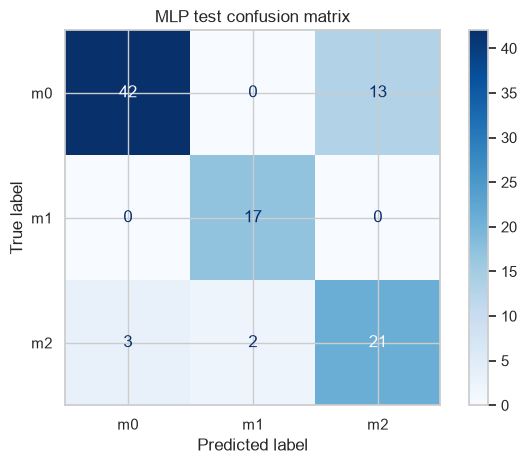

In [46]:
best_model.eval()
all_logits = []
all_targets = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        all_logits.append(best_model(X_batch.to(DEVICE)).cpu())
        all_targets.append(y_batch.cpu())

test_logits = torch.cat(all_logits).numpy()
y_true = torch.cat(all_targets).numpy()
y_pred = test_logits.argmax(axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=3,
))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
)
plt.title("MLP test confusion matrix")
plt.tight_layout()
plt.show()

# Part XVII — Compare with classical models

## 35. Logistic Regression baseline

A neural network is not automatically better than a simpler model.


In [47]:
logreg = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE,
)
logreg.fit(X_train_scaled, y_train)
pred_logreg = logreg.predict(X_test_scaled)

print("Logistic regression balanced accuracy:", balanced_accuracy_score(y_test, pred_logreg))
print("Logistic regression macro F1:", f1_score(y_test, pred_logreg, average="macro"))

Logistic regression balanced accuracy: 0.7740436034553682
Logistic regression macro F1: 0.7501316944688323


## 36. XGBoost baseline and a small hyperparameter search

XGBoost builds trees sequentially, with each new tree correcting errors made by earlier trees. We use a small grid over parameters that are meaningful for XGBoost:

- `n_estimators`: number of boosting trees;
- `max_depth`: maximum depth of each tree;
- `learning_rate`: how strongly each new tree changes the current model.

The grid uses group-aware cross-validation inside the training set. This prevents objects from the same `sample_group` appearing in both a training fold and its validation fold. The held-out validation set is used for a second check, and the test set is used only for the final comparison.

In [48]:
xgb_train_y = y_train.map(class_to_index).to_numpy(dtype=np.int64)
xgb_val_y = y_val.map(class_to_index).to_numpy(dtype=np.int64)

xgb_base = XGBClassifier(
    num_class=n_classes,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0,
)

xgb_param_grid = {
    "n_estimators": [10, 20, 50, 75, 100, 200],
    "max_depth": [2,3, 4, 5, 7, 9],
    "learning_rate": [0.01, 0.05, 0.10],
    "subsample": [0.1, 0.3, 0.5, 0.8],
    "colsample_bytree": [0.1, 0.3, 0.5, 0.8]
}

xgb_cv = GroupKFold(n_splits=3)
xgb_grid = GridSearchCV(
    estimator=xgb_base,
    param_grid=xgb_param_grid,
    scoring="f1_macro",
    cv=xgb_cv,
    n_jobs=1,
    return_train_score=True,
    refit=True,
)
xgb_grid.fit(
    X_train_imputed,
    xgb_train_y,
    groups=groups_train.to_numpy(),
)

print("Best XGBoost parameters:", xgb_grid.best_params_)
print(f"Best group-CV macro F1: {xgb_grid.best_score_:.3f}")

xgb_grid_results = (
    pd.DataFrame(xgb_grid.cv_results_)
    .sort_values("rank_test_score")
    [[
        "params",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "rank_test_score",
    ]]
    .head(10)
)
display(xgb_grid_results)

# GridSearchCV refits the best configuration on all training objects.
xgb_model = xgb_grid.best_estimator_
pred_xgb_val_codes = xgb_model.predict(X_val_imputed).astype(int)
pred_xgb_val = np.asarray(class_names)[pred_xgb_val_codes]

print(
    "Selected XGBoost validation balanced accuracy:",
    balanced_accuracy_score(y_val, pred_xgb_val),
)
print(
    "Selected XGBoost validation macro F1:",
    f1_score(y_val, pred_xgb_val, average="macro"),
)

pred_xgb_codes = xgb_model.predict(X_test_imputed).astype(int)
pred_xgb = np.asarray(class_names)[pred_xgb_codes]

print("Selected XGBoost test balanced accuracy:", balanced_accuracy_score(y_test, pred_xgb))
print("Selected XGBoost test macro F1:", f1_score(y_test, pred_xgb, average="macro"))

Best XGBoost parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 20, 'subsample': 0.5}
Best group-CV macro F1: 0.727


,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
1662,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...",0.726565,0.066378,0.969775,1
1559,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.725766,0.053966,1.000000,2
1483,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.724510,0.072471,0.997600,3
1487,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.723759,0.066638,1.000000,4
1579,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.723144,0.077734,1.000000,5
1686,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...",0.722712,0.070398,0.969487,6
1507,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.722219,0.075201,1.000000,7
1531,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.722219,0.075201,1.000000,7
1647,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...",0.721899,0.074076,1.000000,9
1583,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.721839,0.049169,1.000000,10


Selected XGBoost validation balanced accuracy: 0.685064935064935
Selected XGBoost validation macro F1: 0.650997150997151
Selected XGBoost test balanced accuracy: 0.6884683943507474
Selected XGBoost test macro F1: 0.6525793650793651


## 37. Final comparison

| Model | Balanced accuracy | Macro F1 | Notes |
|---|---:|---:|---|
| Logistic Regression | | | linear baseline |
| XGBoost | | | tuned tree-boosting model |
| MLP | | | neural-network model |

,model,balanced_accuracy,macro_f1
0,MLP,0.857110,0.828148
1,Logistic Regression,0.774044,0.750132
2,XGBoost,0.688468,0.652579


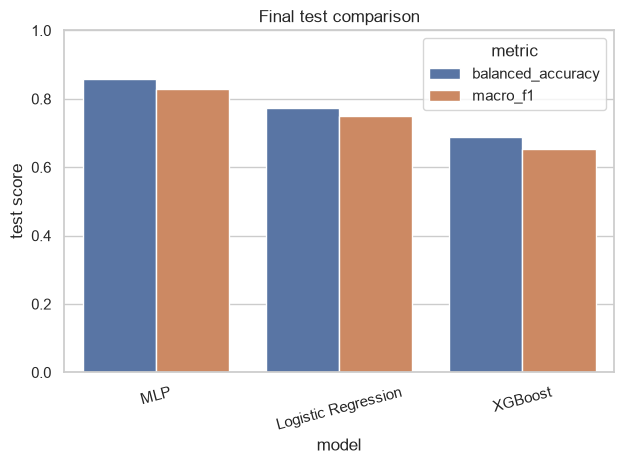

In [49]:
pred_mlp_labels = np.asarray(class_names)[y_pred]

comparison = pd.DataFrame([
    {
        "model": "MLP",
        "balanced_accuracy": balanced_accuracy_score(y_test, pred_mlp_labels),
        "macro_f1": f1_score(y_test, pred_mlp_labels, average="macro"),
    },
    {
        "model": "Logistic Regression",
        "balanced_accuracy": balanced_accuracy_score(y_test, pred_logreg),
        "macro_f1": f1_score(y_test, pred_logreg, average="macro"),
    },
    {
        "model": "XGBoost",
        "balanced_accuracy": balanced_accuracy_score(y_test, pred_xgb),
        "macro_f1": f1_score(y_test, pred_xgb, average="macro"),
    },
]).sort_values("macro_f1", ascending=False).reset_index(drop=True)

display(comparison)

comparison_plot = comparison.melt(
    id_vars="model",
    value_vars=["balanced_accuracy", "macro_f1"],
    var_name="metric",
    value_name="score",
)
sns.barplot(data=comparison_plot, x="model", y="score", hue="metric")
plt.ylim(0, 1)
plt.ylabel("test score")
plt.title("Final test comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Discussion

- Did the MLP outperform the simpler models?
- Was the performance gain worth the added complexity?
- Which model is easier to interpret?
- Which model would you deploy for this biological problem?


# Part XVIII — TensorFlow / Keras comparison

## 38. Same architecture in Keras

We keep PyTorch as the main teaching framework, then show that the same layer and loss ideas exist in Keras.

On native Windows, TensorFlow 2.11 and later does not use CUDA GPU acceleration. A warning about unavailable TensorFlow GPU support is expected on native Windows; it is not the cause of the dtype error. GPU TensorFlow requires WSL2 or an alternative such as DirectML.

In [50]:
import tensorflow as tf
from tensorflow import keras

keras_model = keras.Sequential([
    keras.layers.Input(shape=(input_dim,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(n_classes),
])

keras_model.summary()

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 2,179 (8.51 KB)
 Trainable params: 2,179 (8.51 KB)
 Non-trainable params: 0 (0.00 B)


## 39. Compile and train

In [51]:
# SparseCategoricalCrossentropy expects integer class codes,
# not the original string labels m0, m1, and m2.
y_train_keras = y_train.map(class_to_index).to_numpy(dtype=np.int64)
y_val_keras = y_val.map(class_to_index).to_numpy(dtype=np.int64)
X_train_keras = np.asarray(X_train_scaled, dtype=np.float32)
X_val_keras = np.asarray(X_val_scaled, dtype=np.float32)

keras_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

history_keras = keras_model.fit(
    X_train_keras,
    y_train_keras,
    validation_data=(X_val_keras, y_val_keras),
    epochs=50,
    batch_size=32,
    verbose=1,
)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.3808 - loss: 1.2287 - val_accuracy: 0.2045 - val_loss: 1.2514
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4393 - loss: 1.0752 - val_accuracy: 0.2500 - val_loss: 1.2341
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4979 - loss: 0.9623 - val_accuracy: 0.1818 - val_loss: 1.2240
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5816 - loss: 0.8888 - val_accuracy: 0.2273 - val_loss: 1.2089
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6402 - loss: 0.8297 - val_accuracy: 0.2727 - val_loss: 1.1763
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6862 - loss: 0.7809 - val_accuracy: 0.3182 - val_loss: 1.1460
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7155 - loss: 0.7388 - val_accuracy: 0.3864 - val_loss: 1.1121
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7280 - loss: 0.7023 - val_accuracy: 0.4318 - val_loss: 1.0833
E

## 40. PyTorch vs Keras

| Concept | PyTorch | Keras |
|---|---|---|
| Dense layer | `nn.Linear` | `Dense` |
| Activation | `nn.ReLU()` | `activation="relu"` |
| Loss | explicit object | `compile(loss=...)` |
| Optimizer | explicit object | `compile(optimizer=...)` |
| Training loop | explicit by default | usually hidden in `fit()` |
| Gradients | `loss.backward()` | automatic inside `fit()` |


## 41. Hometask

Same experiment - different representation. Dataset contains same data, but it uses vgg16 embeddings instead of handcrafted morpho characteristics. 
>week6\large_object_vgg3d_embeddings_processed.csv

## Task

Build and evaluate a neural-network classifier for `cell_type` using the VGG3D embedding representation. Compare it with at least one simpler model and explain what the results mean biologically and statistically.

Do not use `sample_group` as a predictive feature. Use it only to construct leakage-safe splits.

## Required sections

### 1. Data inspection and preparation checklist

Since data is the same no need to write detailed report but still - check if everything is in order(just in case)


### 2. Exploratory analysis

Show:

- class counts for `m0`, `m1`, and `m2`;
- the distribution of selected embedding features;
- missingness by feature and by row;
- a two-dimensional t-SNE or UMAP visualization coloured by `cell_type`.

Treat t-SNE/UMAP as exploratory visualizations, not as test-set evaluation.

### 3. Leakage-safe splitting and preprocessing

Create training, validation, and test partitions, be sure that you dont introduce any leakege.



### 4. Baseline and MLP model

Train a simple baseline, such as multinomial logistic regression, followed by a PyTorch MLP

Report training and validation loss and accuracy across epochs.

### 5. Experiments

Perform experiments corresponding to the Week 6 explanations:

- compare at least three learning rates;
- compare at least two network capacities;
- identify possible overfitting from learning curves;
- compare weight decay and dropout;
- demonstrate early stopping;
- explain which configuration you select and why.

Keep the random seed fixed when comparing configurations.

### 6. Classical comparison

Compare the selected MLP with:

- logistic regression;
- XGBoost with a small, validation-only hyperparameter search.


### 7. Evaluation

Evaluate the final selected models on the untouched test partition using:

- balanced accuracy;
- macro F1 score;
- a confusion matrix;
- a short class-by-class error analysis.

Do not select the final model using test performance.

## Questions for the report

1. Did the embedding space show visible separation between the cell types?
2. Which learning rate and architecture performed best, and what evidence supports that choice?
3. Did the MLP overfit? Use the training and validation curves to justify your answer.
4. Which regularization method was most useful?
5. How did the MLP compare with logistic regression and XGBoost?
7. Which cell types were most frequently confused?
8. What additional biological or technical information would help explain the errors?

## Deliverables

- completed notebook;
- short report answering the questions above;
- one table comparing the final models;
- figures for the embedding visualization, learning curves, and confusion matrix;
- a brief statement of limitations and possible next steps.